In [1]:
from google.colab import files
uploaded = files.upload()


Saving time_data.csv to time_data.csv


In [25]:
import pandas as pd

# Load the CSV
df = pd.read_csv("time_data.csv")

# Fix column name in case of BOM (Byte Order Mark)
df.rename(columns={'\ufeffDate': 'Date'}, inplace=True)

# Confirm columns
print("✅ Columns:", df.columns.tolist())
df.head()



✅ Columns: ['Date', 'Revenue']


,Date,Revenue
0,2020-01-31,202
1,2020-02-29,650
2,2020-03-31,1020
3,2020-04-30,1226
4,2020-05-31,1397


In [26]:
# Convert Date to datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Set Date as index
df.set_index('Date', inplace=True)

# Sort by Date
df = df.sort_index()

df.head()


,Revenue
Date,
2020-01-31,202
2020-02-29,650
2020-03-31,1020
2020-04-30,1226
2020-05-31,1397


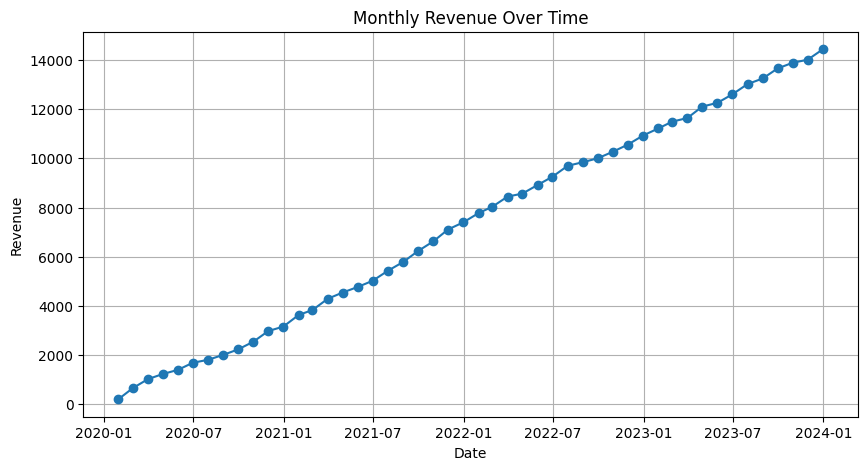

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(df.index, df['Revenue'], marker='o')
plt.title("Monthly Revenue Over Time")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.grid(True)
plt.show()


In [28]:
from statsmodels.tsa.arima.model import ARIMA

# Fit ARIMA model: order=(1,1,1) is a basic choice
model = ARIMA(df['Revenue'], order=(1, 1, 1))
model_fit = model.fit()

# Forecast 6 months
forecast = model_fit.forecast(steps=6)
print("📊 6-Month Forecast:")
print(forecast)


/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


📊 6-Month Forecast:
2024-01-31    14741.095858
2024-02-29    15043.191633
2024-03-31    15345.287326
2024-04-30    15647.382937
2024-05-31    15949.478465
2024-06-30    16251.573910
Freq: ME, Name: predicted_mean, dtype: float64


/tmp/ipython-input-3729271490.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  future_dates = pd.date_range(df.index[-1] + pd.offsets.MonthEnd(1), periods=6, freq='M')


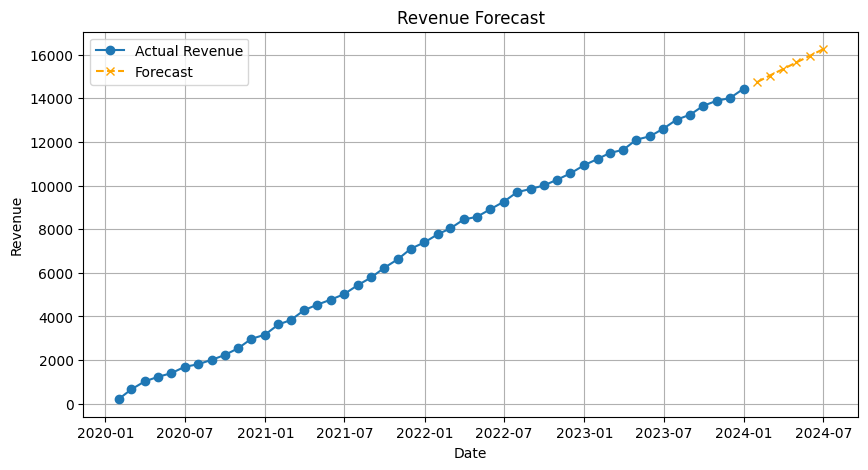

In [29]:
# Create future date index
future_dates = pd.date_range(df.index[-1] + pd.offsets.MonthEnd(1), periods=6, freq='M')

# Plot
plt.figure(figsize=(10, 5))
plt.plot(df.index, df['Revenue'], label='Actual Revenue', marker='o')
plt.plot(future_dates, forecast, label='Forecast', marker='x', linestyle='--', color='orange')
plt.title("Revenue Forecast")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.grid(True)
plt.show()


In [30]:
# Combine future dates and forecast into a DataFrame
forecast_df = pd.DataFrame({
    'Date': future_dates,
    'Forecasted Revenue': forecast
})

# Save to CSV
forecast_df.to_csv('revenue_forecast.csv', index=False)
print("✅ Forecast saved to 'revenue_forecast.csv'")


✅ Forecast saved to 'revenue_forecast.csv'


In [31]:
from google.colab import files
files.download('revenue_forecast.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>